# SOLUTIONS · Programming Assignment 1: Who passes Portuguese?

**Machine Learning with Python** · Minor Amsterdam Data Science and Artificial Intelligence · Fall 2026<br>
Individual · pass/fail · deadline **Sunday, November 15, 2026, 23:59** · hand in the `.ipynb` on Canvas

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/batuatas/MLwPython-labs/blob/main/assignment1_solutions.ipynb)

> **Before you start:** choose **File → Save a copy in Drive** if you want to run or change this notebook.

This notebook is one possible solution. Many choices in the assignment (what to do with the students with `G3 = 0`, which plots to make, which hypotheses to test) can be made differently and still be good, as long as they are explained. The numbers depend on these choices, so yours may differ.


## Setup

Run this cell first. It loads the libraries and downloads the data and the codebook from the course repository.

*Data: P. Cortez (2008), Student Performance, UCI Machine Learning Repository, [doi:10.24432/C5TG7T](https://doi.org/10.24432/C5TG7T), licensed under CC BY 4.0.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error

import urllib.request
DATA = "https://raw.githubusercontent.com/batuatas/MLwPython-labs/main/data/"
students = pd.read_csv(DATA + "student-por.csv", sep=";")          # one row per student
codebook = urllib.request.urlopen(DATA + "student.txt").read().decode("utf-8")

print(students.shape[0], "students,", students.shape[1], "columns")
students.head()

649 students, 33 columns


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


The codebook explains every column. Read it before you start.

In [2]:
print(codebook)

# Attributes for both student-mat.csv (Math course) and student-por.csv (Portuguese language course) datasets:
1 school - student's school (binary: "GP" - Gabriel Pereira or "MS" - Mousinho da Silveira)
2 sex - student's sex (binary: "F" - female or "M" - male)
3 age - student's age (numeric: from 15 to 22)
4 address - student's home address type (binary: "U" - urban or "R" - rural)
5 famsize - family size (binary: "LE3" - less or equal to 3 or "GT3" - greater than 3)
6 Pstatus - parent's cohabitation status (binary: "T" - living together or "A" - apart)
7 Medu - mother's education (numeric: 0 - none,  1 - primary education (4th grade), 2 – 5th to 9th grade, 3 – secondary education or 4 – higher education)
8 Fedu - father's education (numeric: 0 - none,  1 - primary education (4th grade), 2 – 5th to 9th grade, 3 – secondary education or 4 – higher education)
9 Mjob - mother's job (nominal: "teacher", "health" care related, civil "services" (e.g. administrative or police), "at_home" or 

## 4. Exploring and preparing the data

### 4.1 The problem

**Answer.** (a) Examples: the students; features: the 30 columns about the student, the family and school life; label: the final grade `G3`, a number from 0 to 20, so regression. (b) Same examples and features; label: passed or not (`G3` ≥ 10), a category, so classification. A school could use it at the start of the year to offer extra support early. Costs differ: a student predicted to pass who then fails misses the support (costly for the student); a student predicted to fail who would have passed gets support that was not needed (costly for the school, mildly for the student, and possibly stigmatizing). So missing a failing student is the worse mistake.

### 4.2 A first look

In [3]:
print(students.dtypes.value_counts())
print("missing values:", students.isna().sum().sum(), " duplicate rows:", students.duplicated().sum())
display(students.describe())

str      17
int64    16
Name: count, dtype: int64
missing values: 0  duplicate rows: 0


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [4]:
# Run this cell: it prepares the features, so that a model can use them.
# From here on, use `data` (students stays as it was loaded).
data = students.copy()

# yes/no columns -> one column with 1 (yes) and 0 (no).
# The comparison gives True/False, and .astype(int) turns that into 1/0.
yes_no = ["schoolsup", "famsup", "paid", "activities", "nursery", "higher", "internet", "romantic"]
for col in yes_no:
    data[col] = (data[col] == "yes").astype(int)

# the other columns with two values -> one column with 1 and 0 (the value after == becomes 1)
data["school"] = (data["school"] == "MS").astype(int)      # 1: Mousinho da Silveira, 0: Gabriel Pereira
data["sex"] = (data["sex"] == "F").astype(int)             # 1: female, 0: male
data["address"] = (data["address"] == "U").astype(int)     # 1: urban, 0: rural
data["famsize"] = (data["famsize"] == "GT3").astype(int)   # 1: more than 3, 0: 3 or fewer
data["Pstatus"] = (data["Pstatus"] == "T").astype(int)     # 1: parents together, 0: apart

# columns with more than two values -> one 0/1 column per value.
# To leave them out instead: data = data.drop(columns=["Mjob", "Fjob", "reason", "guardian"])
data = pd.get_dummies(data, columns=["Mjob", "Fjob", "reason", "guardian"], dtype=int)

print(data.shape)
data.head()

(649, 46)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,...,Fjob_other,Fjob_services,Fjob_teacher,reason_course,reason_home,reason_other,reason_reputation,guardian_father,guardian_mother,guardian_other
0,0,1,18,1,1,0,4,4,2,2,...,0,0,1,1,0,0,0,0,1,0
1,0,1,17,1,1,1,1,1,1,2,...,1,0,0,1,0,0,0,1,0,0
2,0,1,15,1,0,1,1,1,1,2,...,1,0,0,0,0,1,0,0,1,0
3,0,1,15,1,1,1,4,2,1,3,...,0,1,0,0,1,0,0,0,1,0
4,0,1,16,1,1,1,3,3,1,2,...,1,0,0,0,1,0,0,1,0,0


**Answer.** No missing values and no duplicate rows. 17 columns are text: 8 yes/no columns and 5 other columns with two values became one 0/1 column each; `Mjob`, `Fjob`, `reason` and `guardian` became one 0/1 column per value (17 columns). The numeric columns are counts or ordinal scales (1 to 4 or 1 to 5), which we keep as numbers, as the codebook defines them; a scale such as `studytime` (1: < 2 hours … 4: > 10 hours) is not evenly spaced, which a linear model ignores.

### 4.3 Distributions

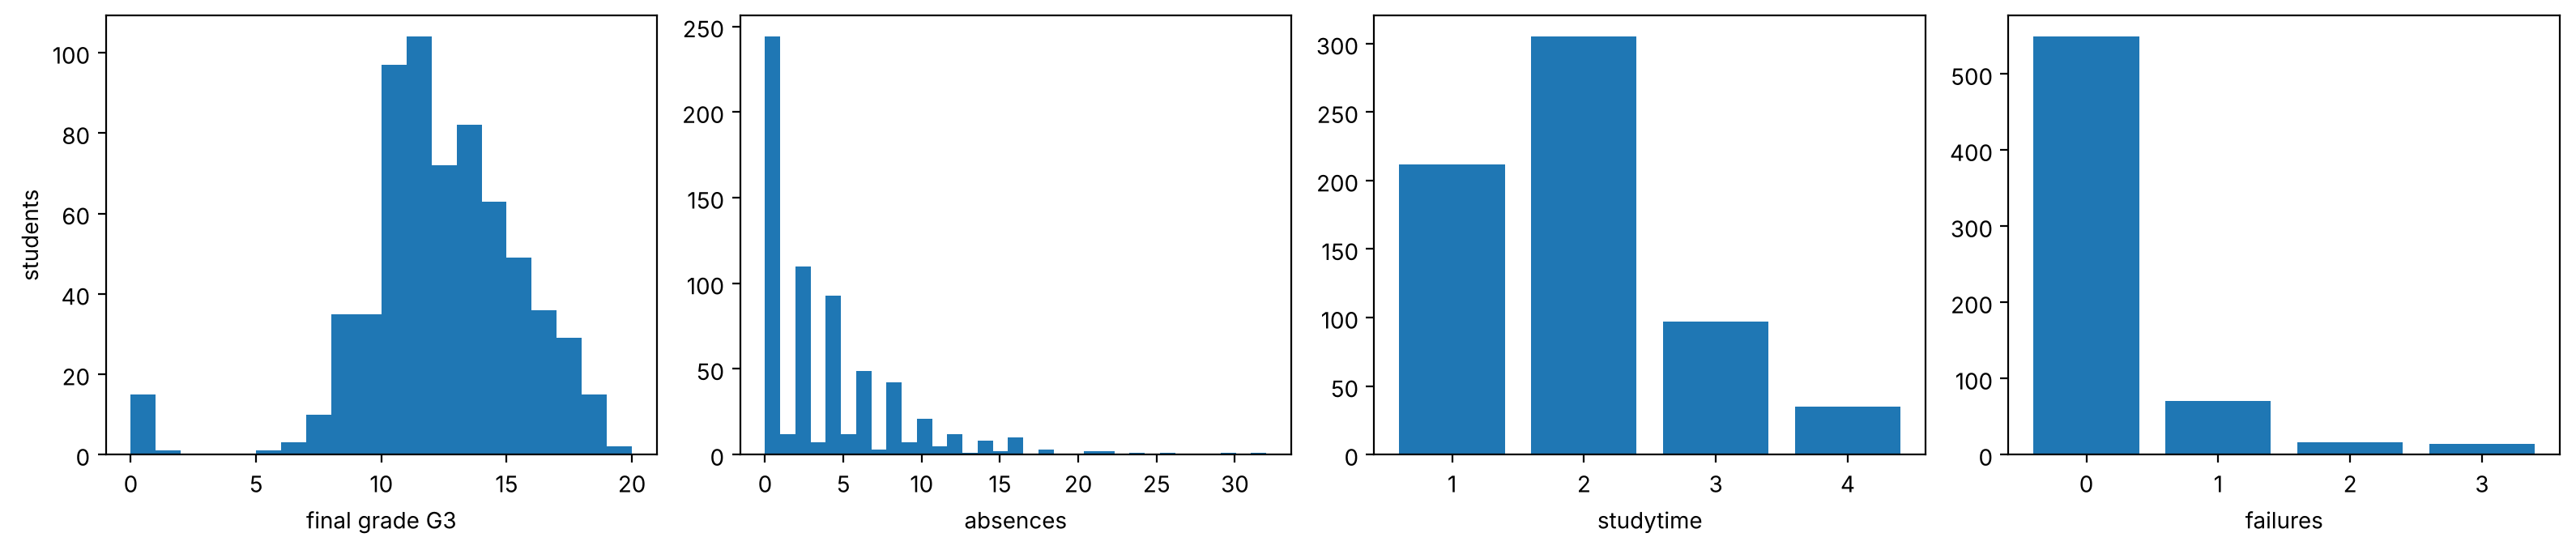

15 students with G3 = 0;  their G1, G2 and absences:
             G1   G2  absences    school
mean   7.066667  3.8       0.0  0.933333
min    4.000000  0.0       0.0  0.000000
max   11.000000  9.0       0.0  1.000000


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].hist(data["G3"], bins=range(0, 21))
axes[0].set_xlabel("final grade G3"); axes[0].set_ylabel("students")
axes[1].hist(data["absences"], bins=33)
axes[1].set_xlabel("absences")
for ax, col in zip(axes[2:], ["studytime", "failures"]):
    counts = data[col].value_counts().sort_index()
    ax.bar(counts.index, counts.values)
    ax.set_xlabel(col)
plt.tight_layout(); plt.show()

zeros = data[data["G3"] == 0]
print(len(zeros), "students with G3 = 0;  their G1, G2 and absences:")
print(zeros[["G1", "G2", "absences", "school"]].describe().loc[["mean", "min", "max"]])

**Answer.** `G3` is roughly bell-shaped around 12, but 15 students have a final grade of exactly 0, far from all others (the lowest other grade is 1). Their period grades are not 0 (`G1` from 4 to 11), all 15 have 0 absences, and 14 of the 15 come from one school (MS). A 0 is most likely not a measured grade but a code: the student did not take the final exam, for example after leaving school, and then absences were no longer recorded. `absences` is skewed to the right; most students study 2–5 hours (`studytime` 2); most have no past failures. **Choice:** for the regression of the grade we drop the 15 students: their 0 is not a grade on the same scale, and it would pull the line (Lecture 4, "Outliers pull the line"). For pass/fail they clearly did not pass, so another defensible choice is to keep them there; we drop them everywhere for one consistent data set, and note that the model then says nothing about drop-outs.

In [6]:
data = data[data["G3"] > 0].reset_index(drop=True)
print(len(data), "students")

634 students


### 4.4 Relationships

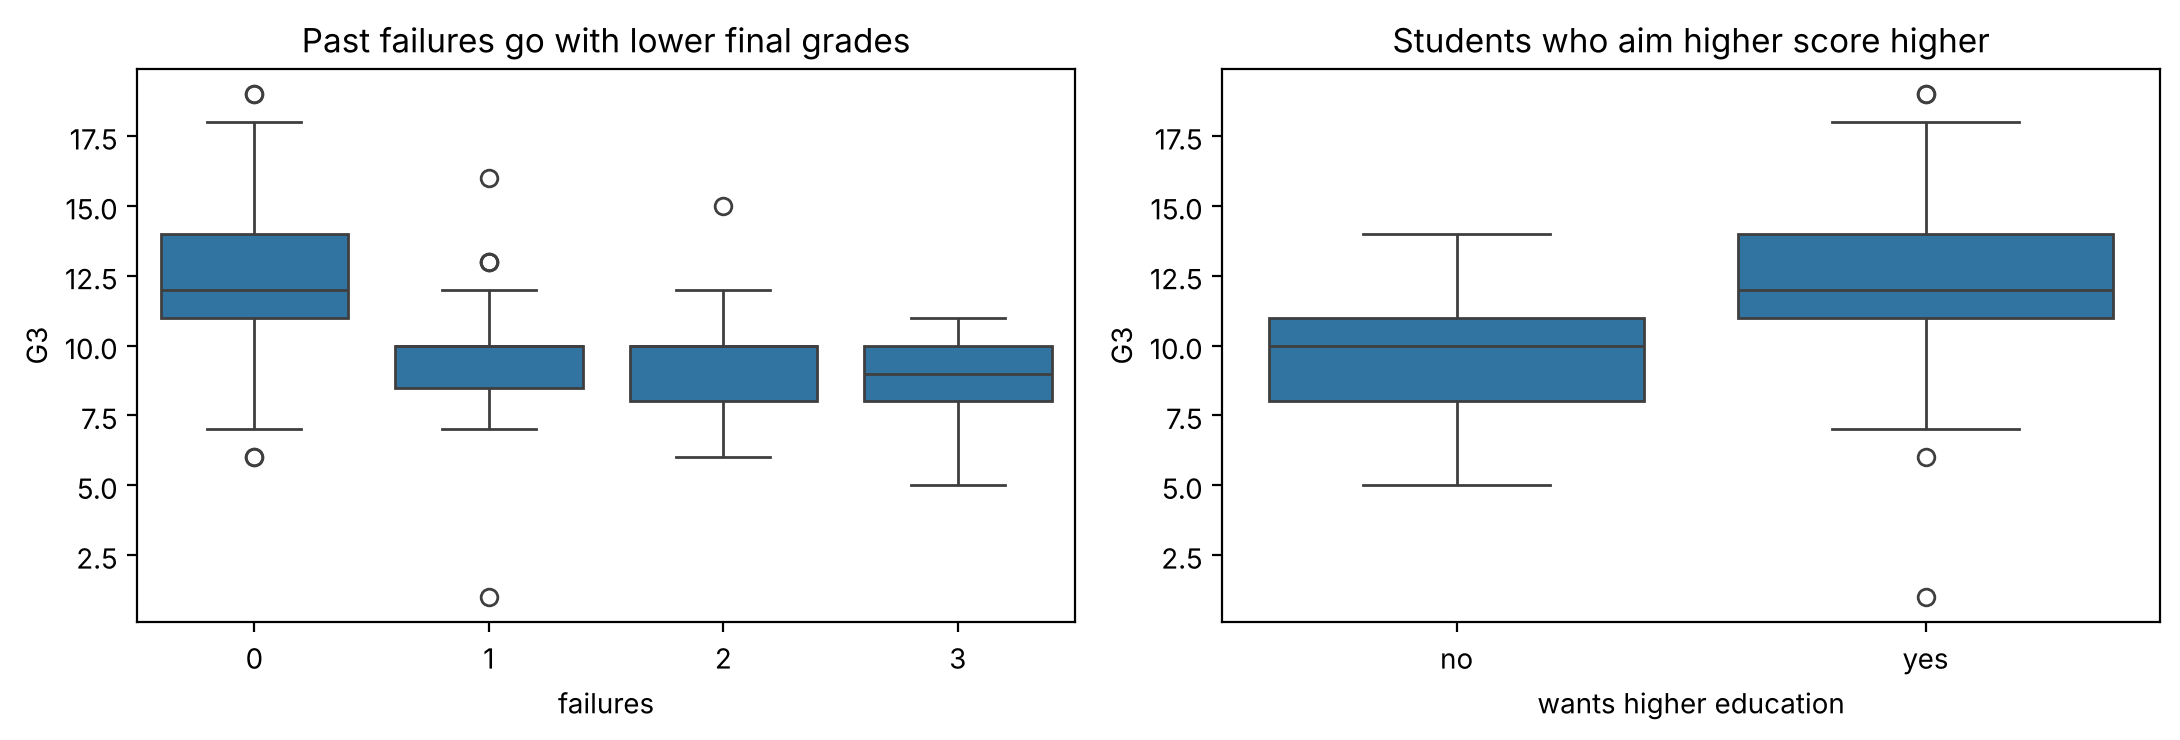

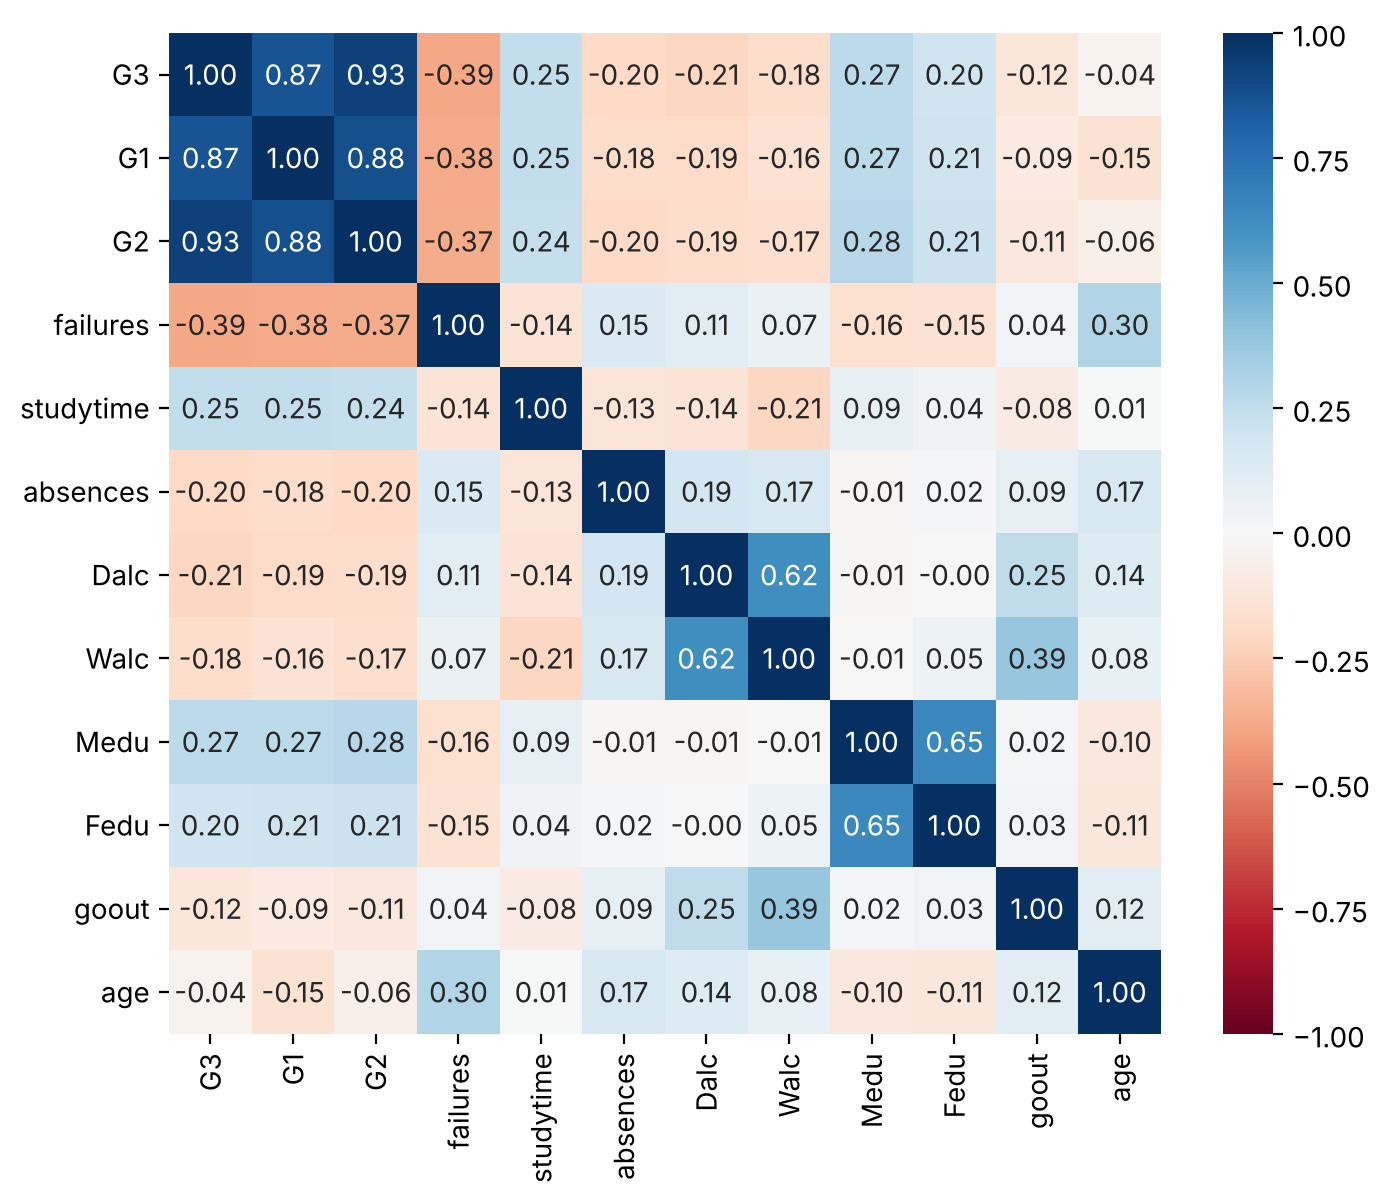

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(data=data, x="failures", y="G3", ax=axes[0])
axes[0].set_title("Past failures go with lower final grades")
sns.boxplot(data=data, x="higher", y="G3", ax=axes[1])
axes[1].set_xticks([0, 1], ["no", "yes"]); axes[1].set_xlabel("wants higher education")
axes[1].set_title("Students who aim higher score higher")
plt.tight_layout(); plt.show()

cols = ["G3", "G1", "G2", "failures", "studytime", "absences", "Dalc", "Walc", "Medu", "Fedu", "goout", "age"]
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(data[cols].corr(), annot=True, fmt=".2f", cmap="RdBu", vmin=-1, vmax=1, ax=ax)
plt.show()

**Answer.** Hypothesis 1: past failures go with lower final grades (median about 12 without failures, about 9–10 with). Hypothesis 2: students who want higher education score higher. The heatmap (diverging colormap, 0 in the middle) shows that `G1` and `G2` are almost the same as `G3` (correlations above 0.8); among the other features, `failures` is the strongest (negative), followed by `higher`, `studytime` and the parents' education (positive) and alcohol use (negative); all are weak to moderate.

### 4.5 Summary

**Answer.** The data are clean in the technical sense (no gaps, no duplicates), but 15 final grades of 0 are a code rather than a grade. Without `G1` and `G2`, every single feature relates only weakly to the final grade, so we expect modest models; the period grades will dominate any model that uses them. 85% of the students pass, so for classification the baseline is high. Open questions: are the 1–5 scales evenly spaced? Is the school (MS has most of the drop-outs) a cause or a proxy?

## 5. Pass or fail: $k$-nearest neighbors

### 5.1 The label and the baseline

In [8]:
features = [c for c in data.columns if c not in ["G1", "G2", "G3"]]
X = data[features]
y = data["G3"] >= 10
print("share passed:", round(y.mean(), 3), "-> baseline accuracy (always 'passed'):", round(y.mean(), 3))

share passed: 0.866 -> baseline accuracy (always 'passed'): 0.866


**Answer.** About 87% of the remaining students passed (85% before dropping the 15 zeros). A model that always says "passed" is right 87% of the time: that is the baseline.

### 5.2 A first $k$-NN

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=0)
knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print("training accuracy:", round(knn.score(X_train, y_train), 3), " test accuracy:", round(knn.score(X_test, y_test), 3))

training accuracy: 0.869  test accuracy: 0.874


**Answer.** Training accuracy 0.87, test accuracy 0.87: no better than the baseline of 87%. With $k = 5$ the majority of the neighbors has almost always passed, so the model predicts "passed" for nearly everybody.

### 5.3 Choosing $k$ honestly

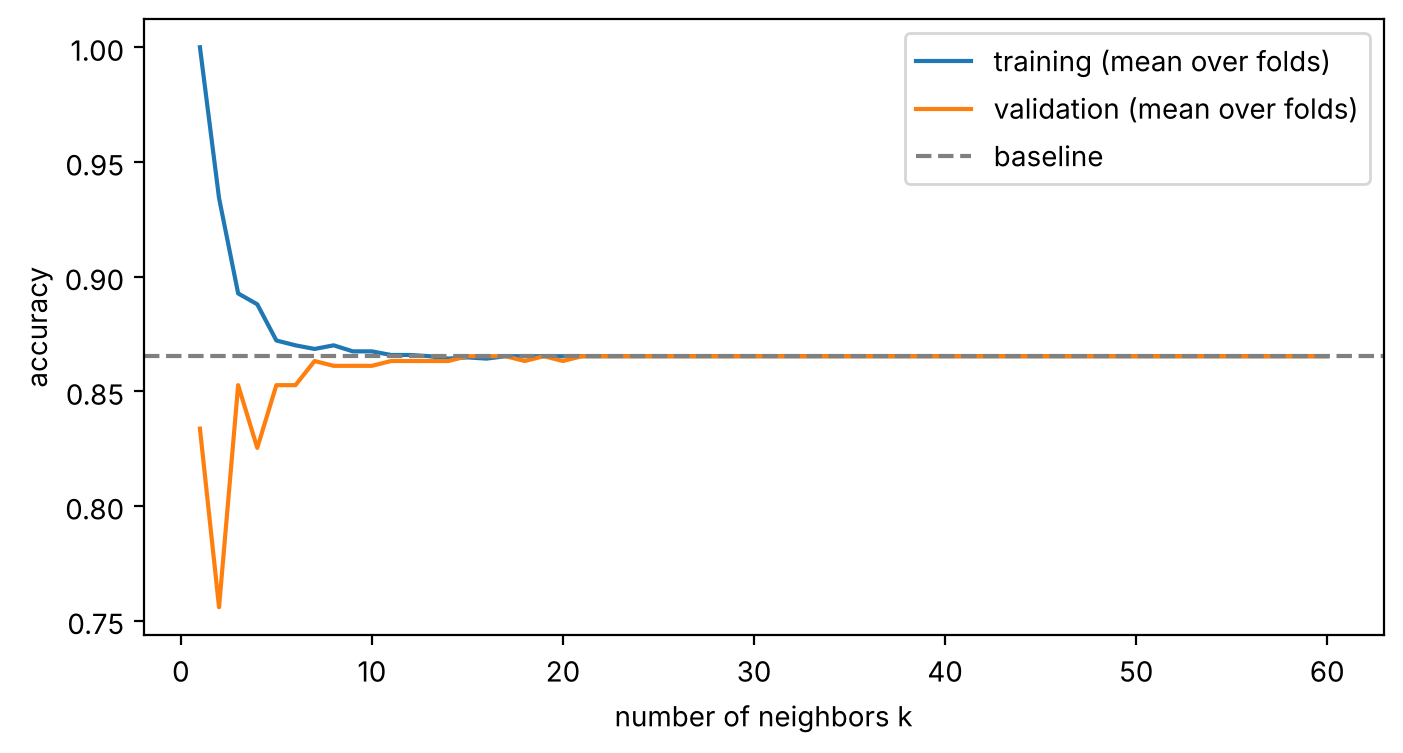

best k: {'n_neighbors': 15}  CV accuracy: 0.865
test accuracy (reported once): 0.874


In [10]:
grid = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": range(1, 61)}, cv=5, return_train_score=True)
grid.fit(X_train, y_train)
res = pd.DataFrame(grid.cv_results_)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(res["param_n_neighbors"], res["mean_train_score"], label="training (mean over folds)")
ax.plot(res["param_n_neighbors"], res["mean_test_score"], label="validation (mean over folds)")
ax.axhline(y_train.mean(), color="grey", linestyle="--", label="baseline")
ax.set_xlabel("number of neighbors k"); ax.set_ylabel("accuracy"); ax.legend(); plt.show()

print("best k:", grid.best_params_, " CV accuracy:", round(grid.best_score_, 3))
print("test accuracy (reported once):", round(grid.score(X_test, y_test), 3))

**Answer.** $k = 1$ overfits: training accuracy 100%, validation 0.83, below the baseline. From $k \approx 15$ on, training and validation accuracy are both 0.865, exactly the share of passing students: the model predicts "passed" for (almost) everybody, which is underfitting. Cross-validation chooses $k = 15$; its test accuracy is 0.874, against 0.868 for always "passed" on the test set, and it flags only 1 of the 21 failing students in the test set. So, without the period grades, $k$-NN on these features is not useful for spotting the students who will fail: an honest and important result, which accuracy alone hides.

### 5.4 Distances and units

**Answer.** `absences` (0 to 32) and `age` (15 to 22) vary over many more units than the 0/1 columns and the 1–5 scales, so they dominate the distance: two students "are near" mostly when their absences are similar, whatever their study time or failures. Lecture 6 puts all features on one scale.

## 6. The final grade: linear models

In [11]:
y_grade = data["G3"]
X_train, X_test, y_train, y_test = train_test_split(X, y_grade, random_state=0)

def scores(model_name, pred_train, pred_test):
    return {"model": model_name,
            "MSE": mean_squared_error(y_test, pred_test), "MAE": mean_absolute_error(y_test, pred_test),
            "R2 test": 1 - mean_squared_error(y_test, pred_test) / y_test.var(ddof=0),
            "R2 train": 1 - mean_squared_error(y_train, pred_train) / y_train.var(ddof=0)}
results = []

### 6.1 Baseline

In [12]:
mean = y_train.mean()
results.append(scores("baseline (mean)", np.full(len(y_train), mean), np.full(len(y_test), mean)))
results[-1]

{'model': 'baseline (mean)',
 'MSE': 7.065301486088606,
 'MAE': 2.172989076464747,
 'R2 test': np.float64(-0.006706308304247344),
 'R2 train': np.float64(0.0)}

### 6.2 Ordinary least squares

In [13]:
ols = LinearRegression().fit(X_train, y_train)
results.append(scores("OLS", ols.predict(X_train), ols.predict(X_test)))
print(results[-1])
coef = pd.Series(ols.coef_, index=features)
coef[["failures", "higher", "Dalc", "studytime", "school"]].round(2)

{'model': 'OLS', 'MSE': 4.850897373641246, 'MAE': 1.7357863642975848, 'R2 test': np.float64(0.3088152010786104), 'R2 train': np.float64(0.4005575070075248)}


failures    -1.37
higher       1.69
Dalc        -0.13
studytime    0.25
school      -0.72
dtype: float64

**Answer.** OLS beats the baseline (test MSE 4.85 against 7.07, MAE 1.74 against 2.17 grade points) but explains only part of the variation: test $R^2$ 0.31, against 0.40 on the training set, some overfitting with 43 features and 475 training students. Coefficients, with care: `failures` about −1.4 points per past failure, with the other features fixed; `higher` about +1.7 points; `school` (1 = Mousinho da Silveira) about −0.7. They describe associations in this sample, not causes: wanting higher education does not *cause* a grade, and the school effect may reflect the students who choose it. Correlated features (`Dalc` and `Walc`, `Medu` and `Fedu`) share the credit, so their individual coefficients are unstable.

### 6.3 Residuals

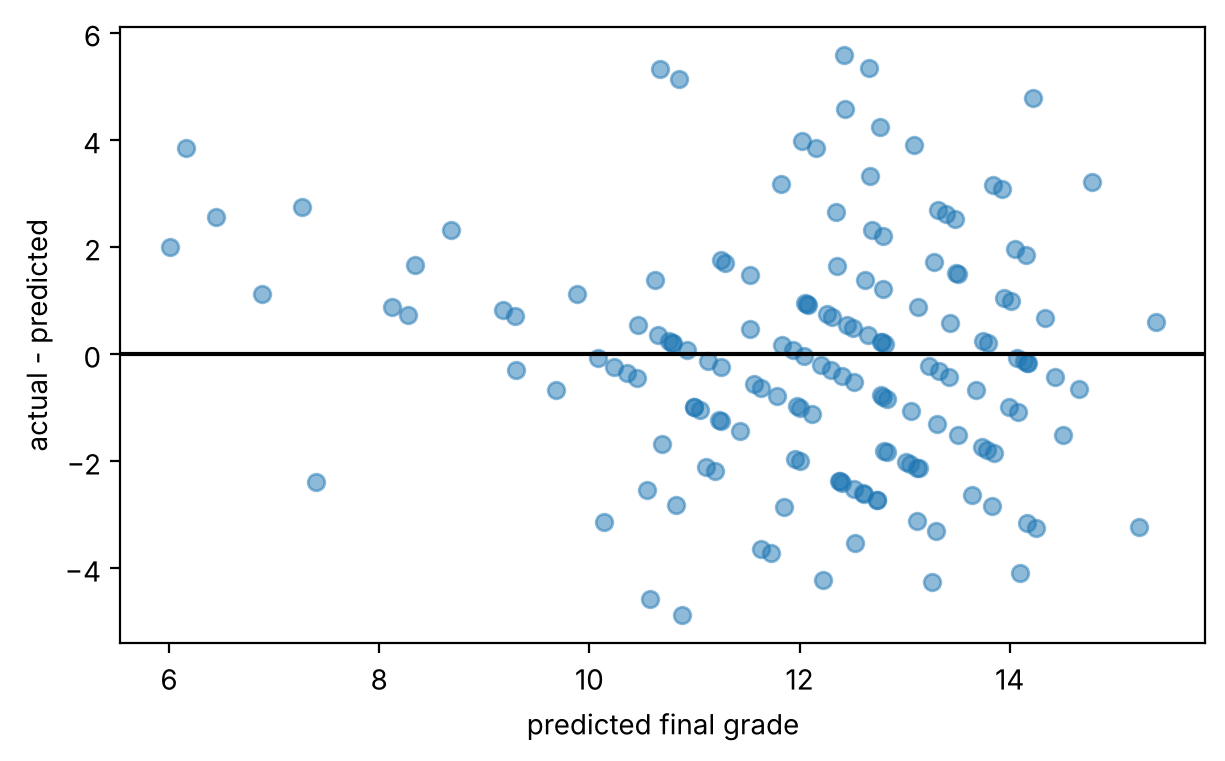

In [14]:
pred = ols.predict(X_test)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(pred, y_test - pred, alpha=0.5)
ax.axhline(0, color="black")
ax.set_xlabel("predicted final grade"); ax.set_ylabel("actual - predicted"); plt.show()

**Answer.** A cloud around 0 without a strong funnel, but the predictions are squeezed into a narrow band (6 to 15) while the actual grades of the test students range from 5 to 19: the model pulls every student towards the average, a sign that the features carry little information about the grade. The large negative residuals belong to students who did much worse than predicted.

### 6.4 Ridge and lasso

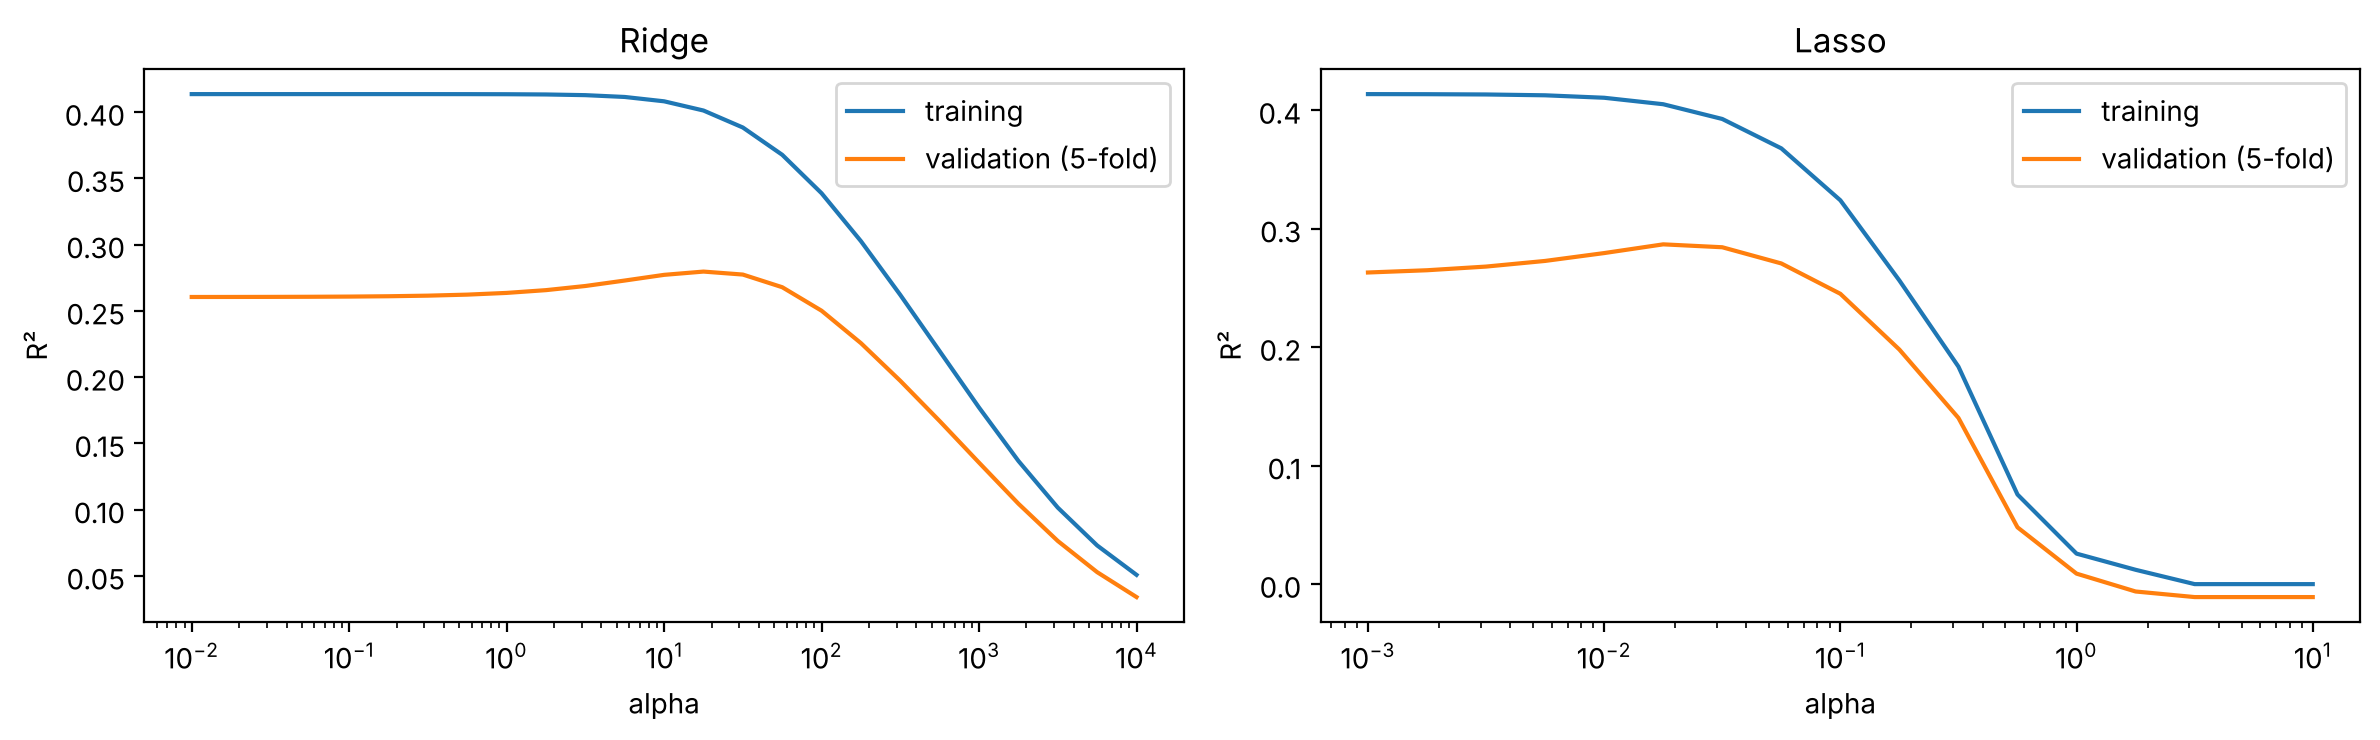

lasso keeps 29 of 43 features:


failures            -1.36
schoolsup           -0.97
school              -0.67
reason_course       -0.30
famsup              -0.20
romantic            -0.19
Fjob_services       -0.16
Dalc                -0.14
goout               -0.14
Pstatus             -0.11
paid                -0.09
health              -0.09
nursery             -0.08
absences            -0.07
Mjob_services       -0.02
Walc                -0.01
freetime            -0.00
famrel               0.15
internet             0.22
studytime            0.23
activities           0.28
reason_reputation    0.29
Medu                 0.29
age                  0.36
Mjob_teacher         0.39
Fjob_teacher         0.43
guardian_father      0.47
sex                  0.77
higher               1.50
dtype: float64

In [15]:
grids = {
    "Ridge": GridSearchCV(Ridge(), {"alpha": np.logspace(-2, 4, 25)}, cv=5, return_train_score=True),
    "Lasso": GridSearchCV(Lasso(max_iter=100000), {"alpha": np.logspace(-3, 1, 17)}, cv=5, return_train_score=True),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (name, g) in zip(axes, grids.items()):
    g.fit(X_train, y_train)
    r = pd.DataFrame(g.cv_results_)
    ax.semilogx(r["param_alpha"].astype(float), r["mean_train_score"], label="training")
    ax.semilogx(r["param_alpha"].astype(float), r["mean_test_score"], label="validation (5-fold)")
    ax.set_title(name); ax.set_xlabel("alpha"); ax.set_ylabel("R²"); ax.legend()
    results.append(scores(f"{name} (alpha={g.best_params_['alpha']:.3g})",
                          g.predict(X_train), g.predict(X_test)))
plt.tight_layout(); plt.show()

lasso_coef = pd.Series(grids["Lasso"].best_estimator_.coef_, index=features)
print("lasso keeps", (lasso_coef != 0).sum(), "of", len(features), "features:")
lasso_coef[lasso_coef != 0].sort_values().round(2)

**Answer.** For small $\alpha$ the training $R^2$ is clearly above the validation $R^2$ (overfitting); for very large $\alpha$ both fall towards 0 (underfitting: all coefficients near zero, the model predicts the mean). The chosen $\alpha$ lies at the top of the validation curve (ridge about 18, lasso about 0.018). With such a small $\alpha$, lasso still keeps 29 of the 43 features; the largest are `failures` (−1.4), `higher` (+1.5), `schoolsup` (−1.0) and `sex` (+0.8; 1 = female). `schoolsup` is a good warning against causal reading: extra support does not lower grades; it is given to students who struggle. Test $R^2$: ridge 0.33, lasso 0.33, OLS 0.31.

### 6.5 Comparison

In [16]:
pd.DataFrame(results).set_index("model").round(3)

,MSE,MAE,R2 test,R2 train
model,,,,
baseline (mean),7.065,2.173,-0.007,0.000
OLS,4.851,1.736,0.309,0.401
Ridge (alpha=17.8),4.697,1.697,0.331,0.392
Lasso (alpha=0.0178),4.729,1.707,0.326,0.394


**Answer.** All three linear models beat the baseline (MAE about 1.7 against 2.2 grade points); the differences between them are small, and the test set is small (159 students), so a difference of 0.02 in $R^2$ means little. We would choose ridge or lasso: as good as OLS on the test set, more stable coefficients, and lasso with fewer features is easier to explain.

### 6.6 The period grades

In [17]:
X_g = data[features + ["G1", "G2"]]
Xg_train, Xg_test = X_g.loc[X_train.index], X_g.loc[X_test.index]
g = GridSearchCV(Lasso(max_iter=100000), {"alpha": np.logspace(-3, 1, 17)}, cv=5).fit(Xg_train, y_train)
p = g.predict(Xg_test)
print("with G1 and G2:  MSE", round(mean_squared_error(y_test, p), 2), " MAE", round(mean_absolute_error(y_test, p), 2),
      " R2", round(g.score(Xg_test, y_test), 3))
c = pd.Series(g.best_estimator_.coef_, index=X_g.columns)
c[c != 0].sort_values().round(2)

with G1 and G2:  MSE 0.75  MAE 0.66  R2 0.893


failures     -0.15
health       -0.05
goout        -0.04
Dalc         -0.03
Walc         -0.01
freetime     -0.00
absences     -0.00
sex           0.03
traveltime    0.04
age           0.10
G1            0.21
G2            0.76
dtype: float64

**Answer.** Test $R^2$ jumps from 0.33 to 0.89 and the MAE drops from 1.7 to 0.66 grade points; lasso keeps 12 features, with `G2` (0.76 per point) and `G1` (0.21) far ahead of all others. The second-period grade is almost the final grade. This model is useful late in the year, for a final check, but it is not available when an early warning would matter most: at the start of the year, `G1` and `G2` do not exist yet. A model may only use what is known at the moment of prediction.

## 7. Interpretation

### 7.1 Hypothesis

**Answer.** "Past failures go with lower grades" is supported: `failures` has one of the largest negative coefficients in OLS, and lasso keeps it at every reasonable $\alpha$. It remains an association, not a cause.

### 7.2 Over- and underfitting

**Answer.** $k$-NN: $k = 1$ overfits (training accuracy near 100%), very large $k$ underfits (always "passed"). Ridge and lasso: small $\alpha$ overfits (gap between training and validation $R^2$), large $\alpha$ underfits (both near 0). The chosen values are those with the best mean cross-validation score, chosen without the test set.

### 7.3 Limitation

**Answer.** The features explain little of the final grade without `G1` and `G2`, and the test set is small, so the scores are uncertain (repeat with other splits, or report cross-validation scores). A next step: put the features on one scale for $k$-NN (Lecture 6), or collect better early indicators, such as a grade from the previous year.

### 7.4 Use

**Answer.** Not as a decision rule. Without the period grades the model hardly beats "everybody passes": the $k$-NN of Part 5 found 1 of 21 failing students in the test set, so many students who need support would be missed. Features such as `sex`, the parents' jobs and education, `romantic` or alcohol use describe who a student is or their family, not what they do at school; using them to allocate support can treat students differently for things they cannot change, and they may encode social inequality (Lecture 4, "Data choices carry values"). At most, the model could start a conversation, with a teacher deciding.

## 8. AI assistance

*(1) Which tools you used, if any, and for what. (2) The most important thing you understood without AI. (3) One mistake or misunderstanding of an AI tool that you noticed and corrected, if any.*

**Answer.** (Each student writes their own.)